# Phase 9 — Arrivals Model Experiments

Learned forecasting of weekly mandi **arrivals** (supply-side market activity, **not demand**) for Onion, Potato and Wheat, under the accepted protocol D-43 and the experiment protocol `phase9-arrivals-protocol-v1` (`Documentation/Phase_09_Model_Protocol.md`), **approved 2026-10-22 as D-44** with the U2–U6 answers.

**Approval gate.** `fit_predict` runs only when `PROTOCOL_STATUS == "APPROVED"` **and** `Decision_Log.md` records D-44 as ACCEPTED. Otherwise the training, evaluation and selection cells skip with a message, and the steps that fit nothing still run:
- loading and validating the data
- building the time-aware features and checking them for leakage
- reproducing the frozen persistence baseline
- preparing the populations

**Fixed by the protocol** (no tuning, no added candidates): the candidates, features, populations, metric, practical threshold and selection rule.

**Never used here:** data after 2020-12-27 (the 2021–2022 test and 2023+ holdout periods are reserved), and no Phase 4–8 output is modified.

## INDEX
1. Setup and configuration
2. Inputs, hashes and the approved Phase 9 dataset
3. Data validation: target, keys, weeks, missing reports, eligibility
4. Time-aware features and the leakage probe
5. Reproducing the frozen persistence baseline
6. Evaluation populations (AQ-1 v1 primary, original as sensitivity)
7. Training candidates (gated)
8. Evaluation, paired uncertainty and the selection rule (gated)
9. Results by year, horizon and crop
10. Saved outputs
11. Summary
12. From proposal to selection (D-45)
13. The one-time reserved test (read-only here)

## 1. Setup and configuration

In [1]:
import os, sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from Code.modelling import dataset as d
from Code.modelling import arrivals as ar
from Code.modelling import arrivals_aq1 as a1
from Code.modelling import arrivals_models as am
from Code.integration.pipeline import file_sha256

random.seed(am.SEED)
np.random.seed(am.SEED)
CROPS = d.load_selected_crops()
FIG = am.OUT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Protocol:", am.PROTOCOL_VERSION, "| status:", am.PROTOCOL_STATUS, "| input cutoff:", ar.CUTOFF.date())
print("Environment:", am.environment(), "| interpreter:", sys.executable)
pd.Series(am.protocol(), dtype=object).to_frame("value")

Protocol: phase9-arrivals-protocol-v1 | status: APPROVED | input cutoff: 2020-12-27
Environment: {'python': '3.13.7', 'pandas': '2.3.3', 'numpy': '2.3.3', 'scikit_learn': '1.8.0'} | interpreter: C:\Python313\python.exe


,value
protocol_version,phase9-arrivals-protocol-v1
status,APPROVED
seed,20261022
cutoff,2020-12-27
candidates,"{'ridge': '[('simpleimputer', SimpleImputer(ad..."
baseline,persistence
exploratory,[calendar_adjusted_persistence]
features,"[f_log_origin, f_origin_reported_days, f_log_n..."
primary_population,aq1_likely
sensitivity_population,original


## 2. Inputs, hashes and the approved Phase 9 dataset

- **Inputs:** the Phase 6 feature tables, hash-checked against the Phase 7 record.
- **Truncation:** the builder truncates every input at 2020-12-27 before computing anything.
- **Prepared per crop:**
  - the weekly examples (D-43)
  - the origin features
  - the AQ-1 v1 flags, verified against their manifest
  - the primary-population target weeks
- **Leakage probe:** runs on a sample of series.

In [2]:
reg = d.registry_columns(pd.read_csv(d.REGISTRY_PATH))
inputs = [d.FEATURE_DIR / f"features_{c.lower()}.parquet" for c in CROPS] + [d.REGISTRY_PATH]
hashes_before = d.check_inputs(inputs, d.phase7_expected_hashes())
manifest = pd.read_csv(a1.AQ_DIR / "aq1_flags_v1_manifest.csv")

DATA, PROBE = {}, []
for crop, path in zip(CROPS, inputs):
    df = pd.read_parquet(path)
    d.validate_schema(df, reg, crop)
    df = df[df["reported_date"] <= ar.CUTOFF]
    by_h, origins = ar.build_arrivals_examples(df)
    feats = am.origin_features(origins, df)
    fpath = a1.AQ_DIR / f"aq1_flags_v1_{crop.lower()}.parquet"
    row = manifest.set_index("crop").loc[crop]
    if not fpath.exists() or file_sha256(fpath) != row["file_sha256"]:
        raise RuntimeError(f"AQ-1 flags for {crop} missing or changed; rerun Code/modelling/arrivals_aq1.py:run_aq1()")
    flags = pd.read_parquet(fpath)
    PROBE.append(am.leakage_probe(df, "2019-06-30", n_series=30).assign(crop=crop))
    DATA[crop] = {"by_h": by_h, "origins": origins, "feats": feats,
                  "weeks": am.population_weeks(flags, am.PRIMARY_POPULATION),               # U2 primary
                  "weeks_mp": am.population_weeks(flags, am.MP_SENSITIVITY_POPULATION),     # U3 sensitivity
                  "pending": int(flags["provider_query_pending"].sum())}
    del df, flags
print("inputs unchanged:", d.check_inputs(inputs) == hashes_before)
pd.DataFrame({c: {f"examples h={h}": len(v["by_h"][h]) for h in d.HORIZONS} | {"series-weeks": len(v["origins"]),
              "provider_query_pending rows": v["pending"]} for c, v in DATA.items()})

inputs unchanged: True


,Onion,Potato,Wheat
examples h=1,442276,444436,475538
examples h=2,429717,432611,458984
examples h=4,414812,418678,439311
series-weeks,491376,487758,548966
provider_query_pending rows,1185,737,2162


## 3. Data validation

- **Target:** the weekly median of usable daily arrivals in week W + h, in tonnes per reported day.
- **Series key:** (crop, state, district, market, variety).
- **Weeks:** Monday–Sunday, with the origin at the end of Sunday.
- **Missing reports:** a day without a record is *not reported*, never zero; a week without a usable record yields no example.
- **Eligibility:** ≥ 365 usable arrival dates on or before the origin.
- **Checks:** `validate_arrivals_examples` enforces all of these and the cutoff.

In [3]:
rows = []
for crop, v in DATA.items():
    for h, ex in v["by_h"].items():
        ar.validate_arrivals_examples(ex)
        for period in ["train", "val_2019", "val_2020"]:
            sel = ex["period"] == period
            rows.append({"crop": crop, "h": h, "period": period, "examples": int(sel.sum()),
                         "origin_eligible": int((sel & ex["eligible_at_origin"]).sum()),
                         "max_target_sunday": ex.loc[sel, "target_sunday"].max().date()})
checks = pd.DataFrame(rows)
assert checks["max_target_sunday"].max() <= ar.CUTOFF.date()
checks.pivot_table(index=["crop", "h"], columns="period", values="origin_eligible")

period       train  val_2019  val_2020
crop   h                              
Onion  1  225270.0   28616.0   26539.0
       2  220529.0   28253.0   25512.0
       4  214644.0   27805.0   23968.0
Potato 1  231994.0   29892.0   25750.0
       2  227447.0   29494.0   25155.0
       4  221723.0   28947.0   24462.0
Wheat  1  234241.0   31862.0   25309.0
       2  229144.0   31442.0   24448.0
       4  222962.0   30901.0   23662.0

In [4]:
rep = pd.concat([v["origins"]["origin_week_reported_days"].value_counts(normalize=True).sort_index().rename(c)
                 for c, v in DATA.items()], axis=1)
print("Share of series-weeks by number of reported days (gaps are not zero):")
rep.round(3)

Share of series-weeks by number of reported days (gaps are not zero):


,Onion,Potato,Wheat
origin_week_reported_days,,,
1,0.149,0.124,0.171
2,0.128,0.105,0.123
3,0.102,0.088,0.116
4,0.119,0.113,0.143
5,0.163,0.165,0.188
6,0.225,0.250,0.226
7,0.115,0.155,0.032


## 4. Time-aware features and the leakage probe

Every feature is computed from weeks up to and including the origin week, on the Phase 5 usable view (`am.FEATURES`):
- origin level: log of the origin-week median, reported days, and the log count of usable dates;
- exact calendar-week lags (1, 2, 4 and 52 weeks) as log ratios to the origin; an unreported week stays missing;
- medians of the previous 4 and 13 reported weeks;
- the number of reported weeks in the last 13;
- price context: a usable price in the origin week, and the 4-week log change of the weekly median price;
- target-week calendar fields.

**The probe** replaces every value after a probe origin with 1e9 and recomputes the features. Features at origins on or before it must not change.

In [5]:
probe = pd.concat(PROBE, ignore_index=True)
assert (probe["rows_changed"] == 0).all(), "future data changed an origin feature"
miss = pd.concat([v["feats"][am.FEATURES[:-3]].isna().mean().rename(c) for c, v in DATA.items()], axis=1)
print("Leakage probe: rows compared per crop", probe.groupby("crop")["rows_compared"].first().to_dict(), "- no changes")
print("Missing share per feature (missing = not reported or no history; never imputed here):")
miss.round(3)

Leakage probe: rows compared per crop {'Onion': 1601, 'Potato': 1370, 'Wheat': 642} - no changes
Missing share per feature (missing = not reported or no history; never imputed here):


,Onion,Potato,Wheat
f_log_origin,0.000,0.000,0.000
f_origin_reported_days,0.000,0.000,0.000
f_log_n_dates,0.000,0.000,0.000
f_lag1_logratio,0.100,0.089,0.134
f_lag2_logratio,0.125,0.113,0.164
f_lag4_logratio,0.156,0.142,0.200
f_lag52_logratio,0.371,0.363,0.392
f_med4_logratio,0.007,0.008,0.009
f_med13_logratio,0.007,0.008,0.009
f_weeks_reported_13,0.000,0.000,0.000


## 5. Reproducing the frozen persistence baseline

Persistence (the origin-week median) is recomputed with the same code and compared with the saved `Processed_Data/modelling/phase09/arrivals_baseline_metrics.csv`. Row counts must match exactly, and log MAE to within 1e-12, which allows only the last-bit change of a CSV float round-trip.

In [6]:
saved = pd.read_csv(ar.OUT_DIR / "arrivals_baseline_metrics.csv")
BASE = {}
for crop, v in DATA.items():
    for h, ex in v["by_h"].items():
        BASE[(crop, h)], _ = ar.validation_predictions(ex, v["origins"], crop, h)
repro = am.reproduce_persistence(pd.concat(BASE.values(), ignore_index=True), saved)
assert repro["reproduced"].all(), "persistence does not reproduce the frozen baseline"
print("Persistence reproduced for", len(repro), "crop x horizon x period cells; identical counts; max |diff| =",
      repro["abs_diff_log_mae"].max(), "(CSV float round-trip)")
repro.pivot_table(index=["crop", "horizon_weeks"], columns="period", values="log_mae").round(4)

Persistence reproduced for 27 crop x horizon x period cells; identical counts; max |diff| = 8.326672684688674e-17 (CSV float round-trip)


period                val_2019  val_2020  val_combined
crop   horizon_weeks                                  
Onion  1                0.2033    0.2089        0.2060
       2                0.2365    0.2469        0.2415
       4                0.2817    0.3095        0.2946
Potato 1                0.1515    0.1780        0.1638
       2                0.1782    0.2171        0.1961
       4                0.2160    0.2700        0.2407
Wheat  1                0.3936    0.3920        0.3929
       2                0.4850    0.4812        0.4834
       4                0.6260    0.6153        0.6214

## 6. Evaluation populations

- **Primary population** (approved, U2): AQ-1 v1 `aq1_likely`.
  - Evaluation targets are cleaned retrospectively.
  - A training target is cleaned only if its flags were knowable by the refit date.
  - Origin inputs and eligibility stay on the Phase 5 view.
- **Sensitivity 1:** the original population (selection criterion 4).
- **Sensitivity 2** (U3): `aq1_likely_excl_mp_pending`, which also excludes every flagged Madhya Pradesh `provider_query_pending` row. Reported only.

In [7]:
pop = pd.read_csv(ar.OUT_DIR / "arrivals_aq1_population_changes.csv")
pop[(pop["variant"] == am.PRIMARY_POPULATION) & (pop["period"] != "val_combined")].pivot_table(
    index=["crop", "horizon_weeks"], columns="period", values=["examples_dropped", "examples_target_changed"])

examples_dropped          examples_target_changed         
period                       val_2019 val_2020                val_2019 val_2020
crop   horizon_weeks                                                           
Onion  1                          6.0     10.0                    99.0     67.0
       2                          5.0     11.0                    93.0     64.0
       4                          5.0     10.0                    91.0     60.0
Potato 1                          0.0      4.0                    33.0     21.0
       2                          2.0      3.0                    32.0     20.0
       4                          2.0      2.0                    30.0     20.0
Wheat  1                         15.0     39.0                   606.0    425.0
       2                         15.0     40.0                   599.0    416.0
       4                         13.0     38.0                   593.0    415.0

## 7. Training candidates (gated)

**Candidates:** `am.CANDIDATES` (Ridge; conservative HistGradientBoosting with the Phase 8 settings and no tuning).
- **Training:** each candidate is trained separately per crop and horizon, with quarterly expanding refits (`fit_predict`), for all three populations.
- **Target:** the log ratio of the target to the origin-week median.
- **Evaluation rows:** origin-eligible 2019–2020 rows only.

`fit_predict` itself refuses to run unless the protocol is approved.

In [8]:
RESULTS = {}
if am.PROTOCOL_STATUS != "APPROVED":
    print(f"{am.PROTOCOL_VERSION} is {am.PROTOCOL_STATUS}: no learned arrivals model is fitted. "
          "Approve the protocol (decision entry) and set PROTOCOL_STATUS = 'APPROVED' to run this cell.")
else:
    for crop, v in DATA.items():
        for h, ex in v["by_h"].items():
            for cand in am.CANDIDATES:
                for pop_name, weeks in [("primary", v["weeks"]), ("original", None), ("mp_excluded", v["weeks_mp"])]:
                    RESULTS[(crop, h, cand, pop_name)] = am.fit_predict(ex, v["origins"], v["feats"], weeks, cand, crop, h)
    print("fitted", len(RESULTS), "candidate x crop x horizon x population runs")

fitted 54 candidate x crop x horizon x population runs


## 8. Evaluation, paired uncertainty and the selection rule (gated)

**Evaluation:** each candidate is compared with persistence on **identical rows**, separately for 2019 and 2020, using log MAE and a paired bootstrap (whole series, with market clusters as a check; 10,000 replicates; seed 20261022).

**A candidate is proposed only if it:**
1. has 95% intervals above 0 in both years under both clusterings;
2. has estimate / SE above the Bonferroni cut-off for the 36-test family;
3. improves by at least **2%** in both years;
4. also improves on the original population.

**Not covered:** cluster resampling does not capture nationwide shocks.

,crop,horizon_weeks,candidate,rel_2019_pct,rel_2020_pct,c1_ci_both_years_both_clusterings,c2_bonferroni,c3_practical,c4_original_population,passes,proposed
0,Onion,1,hgb_conservative,5.897256,4.434948,True,True,True,True,True,True
1,Onion,1,ridge,2.501451,1.823396,True,False,False,True,False,False
2,Onion,2,hgb_conservative,6.244460,5.040665,True,True,True,True,True,True
3,Onion,2,ridge,2.862150,1.900047,True,False,False,True,False,False
4,Onion,4,hgb_conservative,5.856174,7.124470,True,True,True,True,True,True
5,Onion,4,ridge,2.414296,3.727364,True,True,True,True,True,False
6,Potato,1,hgb_conservative,4.446902,3.104211,True,True,True,True,True,True
7,Potato,1,ridge,0.621630,0.028377,False,False,False,False,False,False
8,Potato,2,hgb_conservative,3.856876,4.371639,True,True,True,True,True,True
9,Potato,2,ridge,-0.428952,0.879932,False,False,False,False,False,False


U3 sensitivity (all flagged MP rows excluded; reported only): relative log-MAE improvement %


period                                 val_2019  val_2020
crop   horizon_weeks candidate                           
Onion  1             hgb_conservative      5.96      4.45
                     ridge                 2.59      1.86
       2             hgb_conservative      6.30      5.18
                     ridge                 2.89      2.06
       4             hgb_conservative      5.82      7.15
                     ridge                 2.41      3.76
Potato 1             hgb_conservative      4.52      3.19
                     ridge                 0.68      0.05
       2             hgb_conservative      3.97      4.39
                     ridge                -0.37      0.90
       4             hgb_conservative      2.60      4.70
                     ridge                -2.45      1.17
Wheat  1             hgb_conservative      8.93      6.43
                     ridge                 1.71      0.97
       2             hgb_conservative     11.33      7.27
                     ridge                 2.20      2.11
       4             hgb_conservative     14.96      9.37
                     ridge                 2.78      4.40

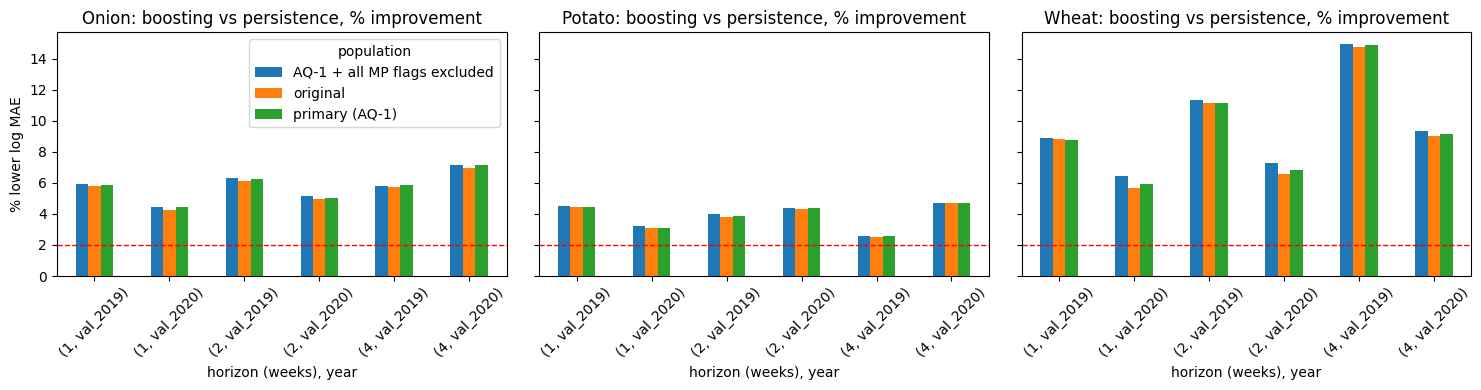

Red dashed line: the pre-specified 2% practical minimum.


In [9]:
SELECTION = pd.DataFrame()
if RESULTS:
    def boot(pop_name):
        out = []
        for (crop, h, cand, p), pr in RESULTS.items():
            if p == pop_name:
                out.append(ar.bootstrap_log_mae(pr, candidate=cand).assign(candidate=cand))
        return pd.concat(out, ignore_index=True)
    BOOT_PRIMARY, BOOT_ORIGINAL, BOOT_MP = boot("primary"), boot("original"), boot("mp_excluded")
    SELECTION = am.select(BOOT_PRIMARY, BOOT_ORIGINAL)          # the D-44 rule: primary + original only
    display(SELECTION)
    mp_view = BOOT_MP[(BOOT_MP["cluster"] == "series") & (BOOT_MP["period"] != "val_combined")]
    print("U3 sensitivity (all flagged MP rows excluded; reported only): relative log-MAE improvement %")
    display(mp_view.pivot_table(index=["crop", "horizon_weeks", "candidate"], columns="period",
                                values="rel_log_mae_improvement_pct").round(2))
    # the same improvement of conservative boosting under the three populations: the conclusion should not depend on them
    sens = pd.concat([b.assign(population=p) for p, b in [("primary (AQ-1)", BOOT_PRIMARY), ("original", BOOT_ORIGINAL),
                                                           ("AQ-1 + all MP flags excluded", BOOT_MP)]])
    sens = sens[(sens["cluster"] == "series") & (sens["period"] != "val_combined") & (sens["candidate"] == "hgb_conservative")]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for ax, crop in zip(axes, CROPS):
        t = sens[sens["crop"] == crop].pivot_table(index=["horizon_weeks", "period"], columns="population", values="rel_log_mae_improvement_pct")
        t.plot(kind="bar", ax=ax, rot=45, legend=(crop == CROPS[0]), title=f"{crop}: boosting vs persistence, % improvement")
        ax.axhline(am.MIN_REL, color="red", ls="--", lw=1); ax.set_xlabel("horizon (weeks), year"); ax.set_ylabel("% lower log MAE")
    fig.tight_layout(); fig.savefig(FIG / "phase09_population_sensitivity.png", dpi=110); plt.show()
    print("Red dashed line: the pre-specified 2% practical minimum.")
else:
    print("No candidate results: the selection rule is defined (am.select) and tested, but not applied.")
    print("Bonferroni family:", am.FAMILY, "tests, z cut-off", round(am.Z_BONFERRONI, 3), "| practical minimum", am.MIN_REL, "%")

## 9. Results by year, horizon and crop

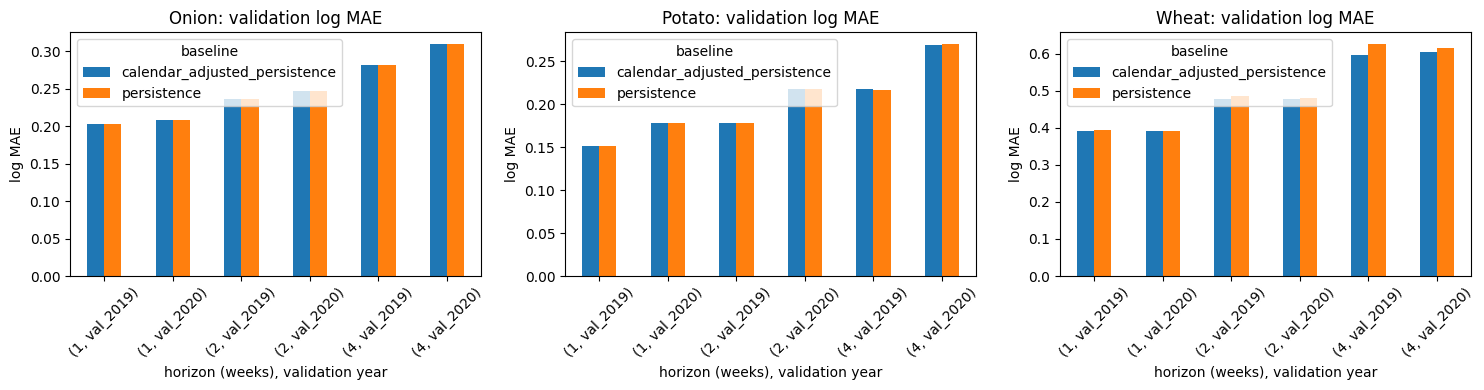

period                                      val_2019  val_2020
crop   h candidate        model                               
Onion  1 hgb_conservative hgb_conservative    0.1901    0.1987
                          persistence         0.2020    0.2079
         ridge            persistence         0.2020    0.2079
                          ridge               0.1969    0.2041
       2 hgb_conservative hgb_conservative    0.2210    0.2331
                          persistence         0.2358    0.2454
         ridge            persistence         0.2358    0.2454
                          ridge               0.2290    0.2408
       4 hgb_conservative hgb_conservative    0.2643    0.2857
                          persistence         0.2807    0.3077
         ridge            persistence         0.2807    0.3077
                          ridge               0.2739    0.2962
Potato 1 hgb_conservative hgb_conservative    0.1446    0.1727
                          persistence         0.1514    0.1782
         ridge            persistence         0.1514    0.1782
                          ridge               0.1504    0.1782
       2 hgb_conservative hgb_conservative    0.1710    0.2074
                          persistence         0.1779    0.2169
         ridge            persistence         0.1779    0.2169
                          ridge               0.1787    0.2150
       4 hgb_conservative hgb_conservative    0.2102    0.2567
                          persistence         0.2157    0.2694
         ridge            persistence         0.2157    0.2694
                          ridge               0.2211    0.2663
Wheat  1 hgb_conservative hgb_conservative    0.3540    0.3638
                          persistence         0.3880    0.3868
         ridge            persistence         0.3880    0.3868
                          ridge               0.3818    0.3839
       2 hgb_conservative hgb_conservative    0.4267    0.4424
                          persistence         0.4802    0.4749
         ridge            persistence         0.4802    0.4749
                          ridge               0.4701    0.4662
       4 hgb_conservative hgb_conservative    0.5288    0.5521
                          persistence         0.6213    0.6076
         ridge            persistence         0.6213    0.6076
                          ridge               0.6048    0.5823

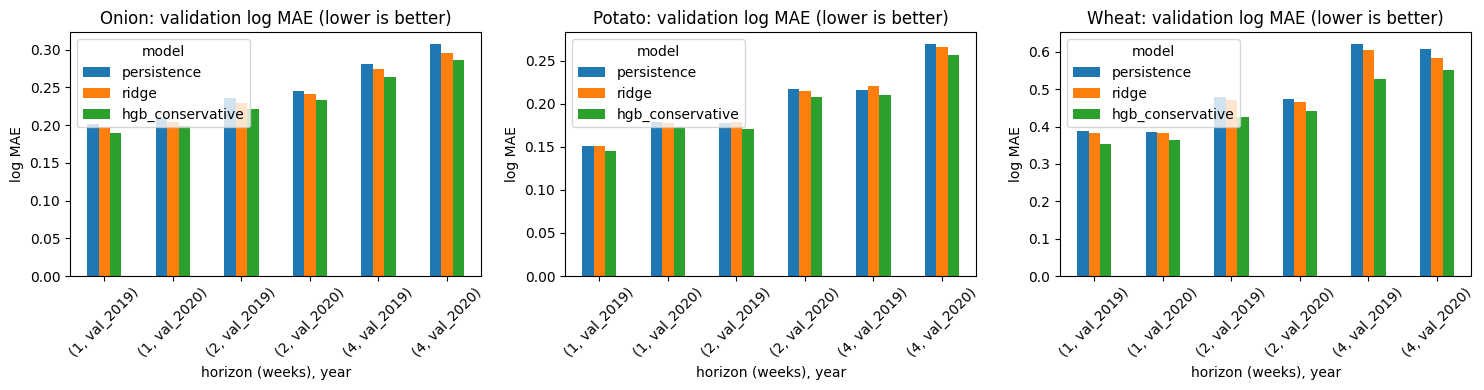

In [10]:
m = saved[(saved["segment"] == "all") & (saved["period"] != "val_combined")
          & saved["baseline"].isin(["persistence", "calendar_adjusted_persistence"])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, crop in zip(axes, CROPS):
    t = m[m["crop"] == crop].pivot_table(index=["horizon_weeks", "period"], columns="baseline", values="log_mae")
    t.plot(kind="bar", ax=ax, rot=45, title=f"{crop}: validation log MAE")
    ax.set_xlabel("horizon (weeks), validation year"); ax.set_ylabel("log MAE")
fig.tight_layout()
fig.savefig(FIG / "phase09_arrivals_baselines.png", dpi=110)
plt.show()
METRICS = pd.DataFrame()
if RESULTS:
    rows = []
    for (crop, h, cand, p), pr in RESULTS.items():
        for period in ["val_2019", "val_2020"]:
            part = pr[pr["period"] == period]
            for name in [cand, "persistence"]:
                rows.append({"crop": crop, "h": h, "candidate": cand, "population": p, "period": period, "model": name,
                             **ar.metrics(part["y"], part[name])})
    METRICS = pd.DataFrame(rows)
    display(METRICS[METRICS["population"] == "primary"].pivot_table(
        index=["crop", "h", "candidate", "model"], columns="period", values="log_mae").round(4))
    # log MAE of persistence, Ridge and conservative boosting per crop, horizon and validation year (primary population)
    prim = METRICS[METRICS["population"] == "primary"].drop_duplicates(["crop", "h", "period", "model"])
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, crop in zip(axes, CROPS):
        t = prim[prim["crop"] == crop].pivot_table(index=["h", "period"], columns="model", values="log_mae")
        t[["persistence", "ridge", "hgb_conservative"]].plot(kind="bar", ax=ax, rot=45, title=f"{crop}: validation log MAE (lower is better)")
        ax.set_xlabel("horizon (weeks), year"); ax.set_ylabel("log MAE")
    fig.tight_layout(); fig.savefig(FIG / "phase09_candidates_log_mae.png", dpi=110); plt.show()

## 10. Saved outputs

**Written to `Processed_Data/modelling/phase09_models/`:**
- the experiment configuration
- the persistence reproduction
- the leakage probe
- the feature missingness

Candidate predictions and metrics are added there only after approval. **No earlier output is overwritten.**

In [11]:
am.write_config()
repro.to_csv(am.OUT_DIR / "persistence_reproduction.csv", index=False)
probe.to_csv(am.OUT_DIR / "feature_leakage_probe.csv", index=False)
miss.to_csv(am.OUT_DIR / "feature_missingness.csv")
if RESULTS:
    pd.concat([pr.assign(candidate=k[2], population=k[3]) for k, pr in RESULTS.items()]).to_parquet(am.OUT_DIR / "candidate_predictions.parquet", index=False)
    BOOT_PRIMARY.to_csv(am.OUT_DIR / "candidate_bootstrap_primary.csv", index=False)
    BOOT_ORIGINAL.to_csv(am.OUT_DIR / "candidate_bootstrap_original.csv", index=False)
    BOOT_MP.to_csv(am.OUT_DIR / "candidate_bootstrap_mp_excluded.csv", index=False)
    METRICS.to_csv(am.OUT_DIR / "candidate_metrics.csv", index=False)
    SELECTION.to_csv(am.OUT_DIR / "candidate_selection.csv", index=False)
print("inputs unchanged:", d.check_inputs(inputs) == hashes_before)
sorted(p.name for p in am.OUT_DIR.iterdir())

inputs unchanged: True


['candidate_bootstrap_mp_excluded.csv',
 'candidate_bootstrap_original.csv',
 'candidate_bootstrap_primary.csv',
 'candidate_metrics.csv',
 'candidate_predictions.parquet',
 'candidate_selection.csv',
 'experiment_config.json',
 'feature_leakage_probe.csv',
 'feature_missingness.csv',
 'figures',
 'persistence_reproduction.csv',
 'test_2021_2022']

## 11. Summary

In [12]:
print("Protocol", am.PROTOCOL_VERSION, "status:", am.PROTOCOL_STATUS)
print("Data: examples built and validated for", ", ".join(CROPS), "with input cutoff", ar.CUTOFF.date())
print("Leakage probe: no feature at or before the probe origin changed when later data changed.")
print("Persistence baseline reproduced (counts identical, |diff| <= 1e-12):", bool(repro["reproduced"].all()))
if SELECTION.empty:
    print("No learned candidate has been fitted: every cell keeps persistence (D-43) until the protocol is approved.")
else:
    for r in SELECTION.itertuples():
        why = [n for n, ok in [("CI both years", r.c1_ci_both_years_both_clusterings), ("Bonferroni", r.c2_bonferroni),
                               ("2% practical", r.c3_practical), ("original population", r.c4_original_population)] if not ok]
        print(f"{r.crop} h={r.horizon_weeks} {r.candidate}: {'PASSES' if r.passes else 'fails: ' + ', '.join(why)}"
              f" ({r.rel_2019_pct:+.2f}% / {r.rel_2020_pct:+.2f}%)")
    print("Candidates passing every criterion:", int(SELECTION["passes"].sum()), "| proposed:",
          SELECTION.loc[SELECTION["proposed"], ["crop", "horizon_weeks", "candidate"]].values.tolist() or "none (persistence kept)")

Protocol phase9-arrivals-protocol-v1 status: APPROVED
Data: examples built and validated for Onion, Potato, Wheat with input cutoff 2020-12-27
Leakage probe: no feature at or before the probe origin changed when later data changed.
Persistence baseline reproduced (counts identical, |diff| <= 1e-12): True
Onion h=1 hgb_conservative: PASSES (+5.90% / +4.43%)
Onion h=1 ridge: fails: Bonferroni, 2% practical (+2.50% / +1.82%)
Onion h=2 hgb_conservative: PASSES (+6.24% / +5.04%)
Onion h=2 ridge: fails: Bonferroni, 2% practical (+2.86% / +1.90%)
Onion h=4 hgb_conservative: PASSES (+5.86% / +7.12%)
Onion h=4 ridge: PASSES (+2.41% / +3.73%)
Potato h=1 hgb_conservative: PASSES (+4.45% / +3.10%)
Potato h=1 ridge: fails: CI both years, Bonferroni, 2% practical, original population (+0.62% / +0.03%)
Potato h=2 hgb_conservative: PASSES (+3.86% / +4.37%)
Potato h=2 ridge: fails: CI both years, Bonferroni, 2% practical, original population (-0.43% / +0.88%)
Potato h=4 hgb_conservative: PASSES (+2.57%

## 12. From proposal to selection (D-45)

**Sections 7–11 are validation results:** 2019–2020, used to select. A candidate that passed every criterion was first only a **proposed** selection (protocol §5).

**The decision record:**
- **D-45** (`Documentation/Decision_Log.md`) proposed conservative boosting for all nine cells.
- The project owner **accepted D-45 as written on 2026-10-23**, before any arrivals test data was read.
- The selection was then **frozen by hash**, and the reserved 2021–2022 test was run **once** (section 13).
- The test result cannot change the selection.

## 13. The one-time reserved 2021–2022 test (read-only here)

**How it was run:** by `Code/modelling/arrivals_final.py:run_test()`, exactly once, after these steps:
1. D-45 acceptance;
2. a freeze manifest covering code, protocol, inputs, AQ-1 files, validation outputs and both decision texts;
3. a persistent run-once guard.

**Limits it kept to:**
- Only rows dated up to the last test week were read; the 2023+ holdout was never loaded.
- The models are the frozen D-45 selection; nothing was tuned.

**This notebook only reads the saved results.** It verifies the freeze and the run log, and never re-runs the test.

In [13]:
from Code.modelling import arrivals_final as af
af.verify_freeze()                                          # code, decisions, inputs and validation outputs unchanged
run_log = pd.read_csv(af.TEST_DIR / "run_log.csv")
assert run_log["status"].tolist() == ["started", "completed"], "the one-time test did not complete exactly once"
TM = pd.read_csv(af.TEST_DIR / af.RESULTS)
TB = pd.read_csv(af.TEST_DIR / "test_bootstrap.csv")
AUD = pd.read_csv(af.TEST_DIR / "test_access_audit.csv")
print("Run log:", run_log[["utc", "status"]].values.tolist())
print("Rows read after the last test week:", int(AUD["rows_after_2022_12_25_read"].sum()),
      "| latest date read:", AUD["max_reported_date_read"].max(),
      "| scored target weeks:", AUD["first_scored_target_sunday"].min(), "to", AUD["last_scored_target_sunday"].max())

Run log: [['2026-10-22T20:39:23+00:00', 'started'], ['2026-10-22T20:48:08+00:00', 'completed']]
Rows read after the last test week: 0 | latest date read: 2022-12-25 | scored target weeks: 2021-01-03 to 2022-12-25


In [14]:
# Primary population (AQ-1): boosting vs persistence on identical rows, per crop, horizon and test year
ci = TB[TB["cluster"] == "series"].set_index(["crop", "horizon_weeks", "population", "period"])
mk = TB[TB["cluster"] == "market"].set_index(["crop", "horizon_weeks", "population", "period"])["verdict"].rename("verdict_market")
T = TM.set_index(["crop", "horizon_weeks", "population", "period"]).join(ci[["rel_ci_low", "rel_ci_high", "verdict"]]).join(mk).reset_index()
prim_t = T[(T["population"] == "primary") & (T["period"] != "test_combined")]
prim_t[["crop", "horizon_weeks", "period", "n", "n_series", "persistence_log_mae", "log_mae", "rel_log_mae_improvement_pct",
        "rel_ci_low", "rel_ci_high", "verdict", "verdict_market", "persistence_mae_t_per_day", "mae_t_per_day"]].round(3)

,crop,horizon_weeks,period,n,n_series,persistence_log_mae,log_mae,rel_log_mae_improvement_pct,rel_ci_low,rel_ci_high,verdict,verdict_market,persistence_mae_t_per_day,mae_t_per_day
6,Onion,1,test_2021,29888,789,0.183,0.177,3.380,2.225,4.523,better,better,27.278,26.468
7,Onion,1,test_2022,34034,856,0.184,0.173,6.341,5.228,7.392,better,better,33.975,31.726
15,Onion,2,test_2021,29453,780,0.218,0.210,3.851,2.774,4.907,better,better,32.377,32.379
16,Onion,2,test_2022,33640,847,0.213,0.201,5.814,4.753,6.866,better,better,39.210,36.713
24,Onion,4,test_2021,28906,771,0.266,0.255,4.108,2.939,5.231,better,better,40.221,39.445
25,Onion,4,test_2022,33089,845,0.252,0.240,4.571,3.324,5.748,better,better,46.995,44.782
33,Potato,1,test_2021,29125,764,0.153,0.149,3.194,1.963,4.402,better,better,9.747,9.527
34,Potato,1,test_2022,32380,826,0.156,0.150,4.118,2.985,5.242,better,better,15.359,14.622
42,Potato,2,test_2021,28707,756,0.185,0.180,2.958,1.791,4.071,better,better,12.594,12.128
43,Potato,2,test_2022,31999,815,0.187,0.179,4.227,3.030,5.396,better,better,19.979,19.307


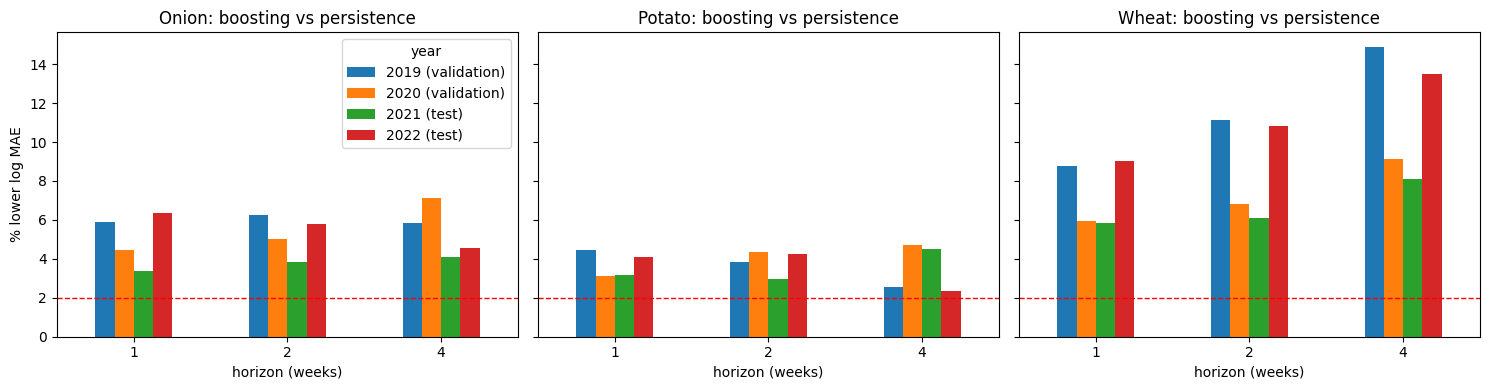

Test: cells with 95% interval above 0 (series / market): 18 / 18 of 18 | cells >= 2% practical minimum: 18 of 18


In [15]:
# Validation (selection) vs the one-time test, side by side: % lower log MAE than persistence
val = pd.read_csv(am.OUT_DIR / "candidate_selection.csv")
val = val[val["proposed"]].melt(id_vars=["crop", "horizon_weeks"], value_vars=["rel_2019_pct", "rel_2020_pct"],
                                var_name="year", value_name="improvement_pct")
val["year"] = val["year"].str.slice(4, 8) + " (validation)"
tst = prim_t.assign(year=prim_t["period"].str.slice(5, 9) + " (test)")[["crop", "horizon_weeks", "year", "rel_log_mae_improvement_pct"]]
both = pd.concat([val, tst.rename(columns={"rel_log_mae_improvement_pct": "improvement_pct"})])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, crop in zip(axes, CROPS):
    t = both[both["crop"] == crop].pivot_table(index="horizon_weeks", columns="year", values="improvement_pct")
    t.plot(kind="bar", ax=ax, rot=0, legend=(crop == CROPS[0]), title=f"{crop}: boosting vs persistence")
    ax.axhline(am.MIN_REL, color="red", ls="--", lw=1); ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("% lower log MAE")
fig.tight_layout(); fig.savefig(FIG / "phase09_validation_vs_test.png", dpi=110); plt.show()
print("Test: cells with 95% interval above 0 (series / market):", int((prim_t["verdict"] == "better").sum()), "/",
      int((prim_t["verdict_market"] == "better").sum()), "of", len(prim_t),
      "| cells >= 2% practical minimum:", int((prim_t["rel_log_mae_improvement_pct"] >= am.MIN_REL).sum()), "of", len(prim_t))

In [16]:
# Sensitivity on the test years: original population and all flagged Madhya Pradesh rows excluded (U3)
sens_t = T[T["period"] != "test_combined"].pivot_table(index=["crop", "horizon_weeks", "period"], columns="population",
                                                       values="rel_log_mae_improvement_pct").round(2)
print("Largest difference between populations (percentage points):", round(float((sens_t.max(axis=1) - sens_t.min(axis=1)).max()), 2))
print("Cells with interval above 0, by population:", T[T["period"] != "test_combined"].groupby("population")["verdict"]
      .apply(lambda v: int((v == "better").sum())).to_dict())
sens_t

Largest difference between populations (percentage points): 0.61
Cells with interval above 0, by population: {'mp_excluded': 18, 'original': 18, 'primary': 18}


population                      mp_excluded  original  primary
crop   horizon_weeks period                                   
Onion  1             test_2021         3.35      3.17     3.38
                     test_2022         6.24      5.90     6.34
       2             test_2021         3.88      3.59     3.85
                     test_2022         5.75      5.48     5.81
       4             test_2021         4.10      3.90     4.11
                     test_2022         4.58      4.36     4.57
Potato 1             test_2021         3.16      3.15     3.19
                     test_2022         4.03      4.04     4.12
       2             test_2021         2.99      3.02     2.96
                     test_2022         4.23      4.14     4.23
       4             test_2021         4.46      4.38     4.49
                     test_2022         2.29      2.20     2.34
Wheat  1             test_2021         5.96      5.45     5.83
                     test_2022         9.06      8.45     9.00
       2             test_2021         6.13      5.66     6.10
                     test_2022        10.94     10.36    10.84
       4             test_2021         8.23      7.93     8.10
                     test_2022        13.49     13.18    13.49

**Reading the test.**
- **The evidence:** the gains seen in validation **held on two unseen years**. Statistically, every interval excludes zero. Practically, the gains are modest: a few percent lower log error for Onion and Potato, and more for Wheat.
- **Tonnes per day:** a smaller log error does not always mean a smaller absolute error. In a few cells the MAE in tonnes is almost unchanged.
- **Unchanged from before:**
  - The intervals cover variation across series, not nationwide shocks.
  - The `provider_query_pending` marker covers 2019–2020 only, so it changes training targets, not test targets.
  - Arrivals are a supply-side measure, not demand.
  - The 2023+ holdout remains unscored and reserved.